In [6]:
import numpy as np
import matplotlib.pyplot as plt

(200, 200, 3) uint8 120000 bytes


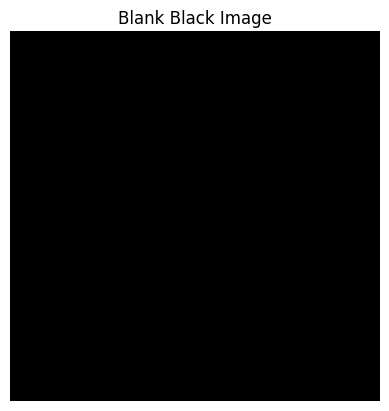

In [7]:

img = np.zeros((200, 200, 3), dtype=np.uint8)
print(img.shape, img.dtype, img.nbytes, "bytes")

plt.imshow(img); plt.title("Blank Black Image"); plt.axis("off"); plt.show()

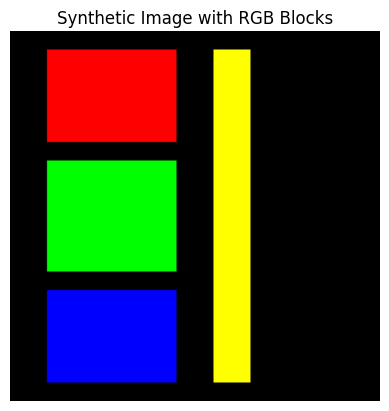

In [8]:
img = np.zeros((200, 200, 3), dtype=np.uint8)

img[10:60,  20:90]  = [255, 0, 0]    # Red
img[70:130, 20:90]  = [0, 255, 0]    # Green
img[140:190,20:90]  = [0, 0, 255]    # Blue
img[10:190, 110:130]= [255, 255, 0]  # Yellow stripe

plt.imshow(img); plt.title("Synthetic Image with RGB Blocks"); plt.axis("off"); plt.show()

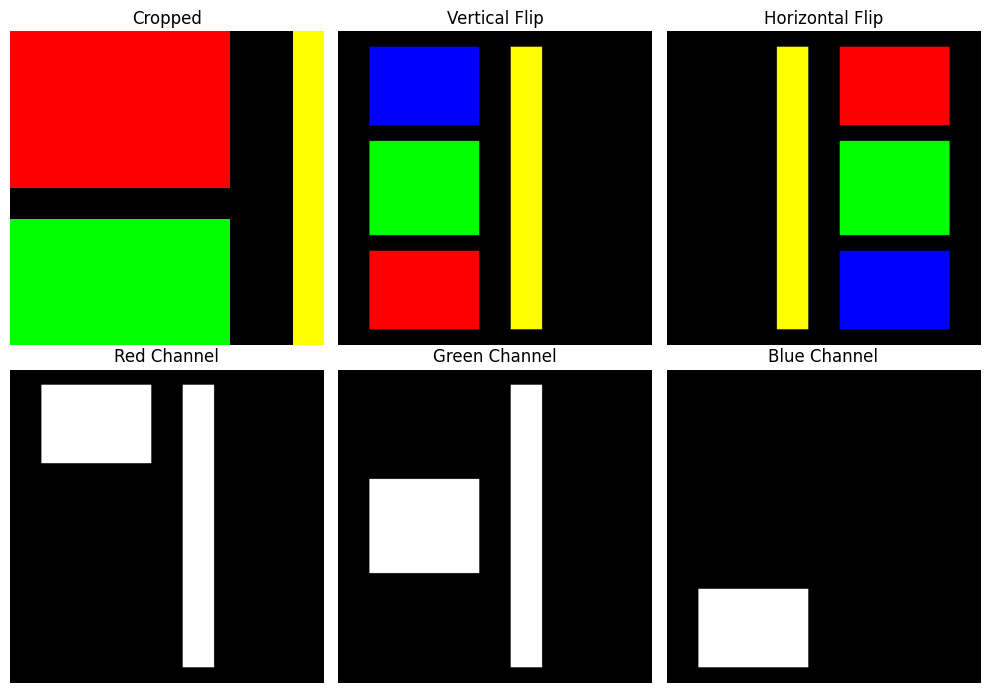

In [9]:
images = [
    (img[10:110, 20:120],   "Cropped"),
    (img[::-1],             "Vertical Flip"),
    (img[:, ::-1],          "Horizontal Flip"),
    (img[:, :, 0],          "Red Channel"),
    (img[:, :, 1],          "Green Channel"),
    (img[:, :, 2],          "Blue Channel"),
]

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, (im, title) in zip(axes.flat, images):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout(); plt.show()

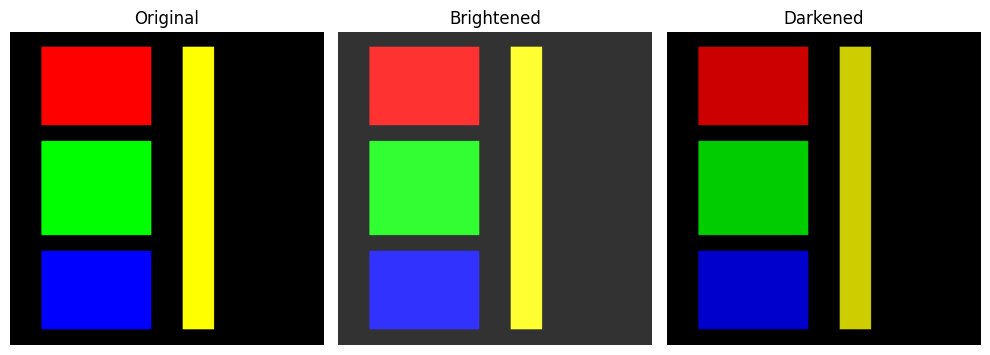

In [10]:
f = img.astype(np.float32)

images = [
    (img,                                "Original"),
    (np.clip(f + 50, 0, 255).astype(np.uint8), "Brightened"),
    (np.clip(f - 50, 0, 255).astype(np.uint8), "Darkened"),
]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))
for ax, (im, title) in zip(axes, images):
    ax.imshow(im); ax.set_title(title); ax.axis("off")

plt.tight_layout(); plt.show()

Bright pixels: 0 | Mask shape: (200, 200)


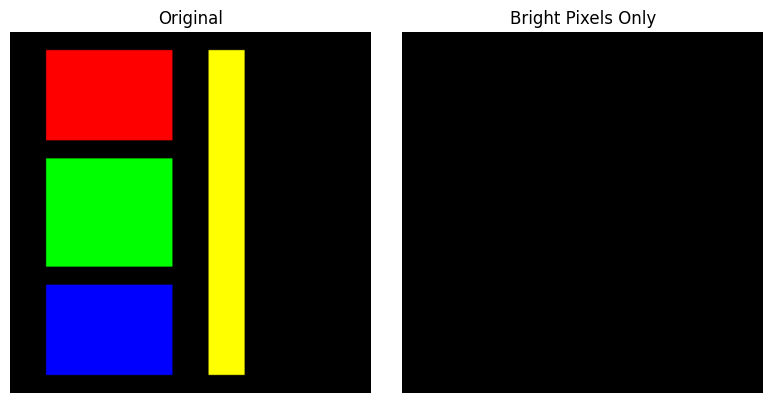

In [11]:
mask = img.mean(axis=2) > 180
print("Bright pixels:", np.count_nonzero(mask), "| Mask shape:", mask.shape)

masked = np.zeros_like(img)
masked[mask] = img[mask]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, (im, title) in zip(axes, [(img, "Original"), (masked, "Bright Pixels Only")]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")

plt.tight_layout(); plt.show()

In [12]:
u8 = np.zeros((200, 200, 3), dtype=np.uint8)
f64 = np.zeros((200, 200, 3), dtype=np.float64)

print(f"uint8:   {u8.nbytes} B  |  {u8.nbytes/1024} KB")
print(f"float64: {f64.nbytes} B  |  {f64.nbytes/1024} KB")
print(f"Ratio:   {f64.nbytes // u8.nbytes}x")

uint8:   120000 B  |  117.1875 KB
float64: 960000 B  |  937.5 KB
Ratio:   8x


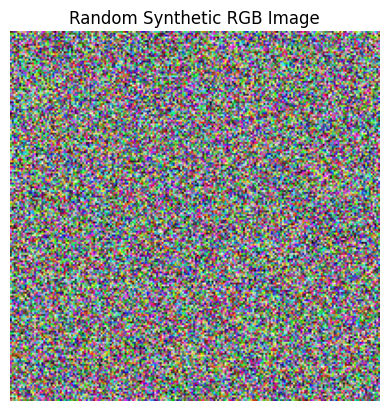

In [13]:
plt.imshow(np.random.randint(0, 256, (200, 200, 3), dtype=np.uint8))
plt.title("Random Synthetic RGB Image"); plt.axis("off"); plt.show()